In [1]:
import pyro
import torch

import matplotlib.pyplot as plt

from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide, posterior_samples
from mmbo.examples.demo import paciorek_demo, branin_demo
from mmbo.training import do_svi

#device = "cuda:3"

## Get training data

In [2]:
X_train_main = branin_demo['X_train_main']
X_train_mm = branin_demo['X_train_mm']
X_test = branin_demo['X_test']
Y_train_main = branin_demo['Y_train_main']
Y_train_mm = branin_demo['Y_train_mm']
Y_test_main = branin_demo['Y_test_main']
Y_test_mm = branin_demo['Y_test_mm']

## Train uni-modal model

In [3]:
model = RegBNN.from_data(X_train = X_train_main, Y_train = Y_train_main, hidden_widths=[256,256])
guide = RegBNNGuide(model)

#model = model.to(device)
#guide = guide.to(device)

In [4]:
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

svi = pyro.infer.SVI(model, guide, adam, elbo)
params, losses = do_svi(svi, params = None)

2025-09-18 09:54:29 - Start


/home/itaylor/projects/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:275: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


2025-09-18 09:56:06 - Step 1000, Elbo loss: 48030.5 +/- 29532.3 (slope = -50670.215 +/- 431.149 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:56:35 - Step 2000, Elbo loss: 16187.7 +/- 10175.9 (slope = -17444.069 +/- 155.608 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:57:04 - Step 3000, Elbo loss: 5391.9 +/- 3369.9 (slope = -5771.845 +/- 53.712 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:57:33 - Step 4000, Elbo loss: 1839.8 +/- 1105.1 (slope = -1890.466 +/- 18.598 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:58:01 - Step 5000, Elbo loss: 675.4 +/- 367.6 (slope = -626.241 +/- 7.185 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:58:32 - Step 6000, Elbo loss: 281.5 +/- 132.0 (slope = -221.547 +/- 3.549 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:59:02 - Step 7000, Elbo loss: 135.5 +/- 55.9 (slope = -87.633 +/- 2.606 loss/k-iter, p-value = 0.000) + 
2025-09-18 09:59:31 - Step 8000, Elbo loss: 78.0 +/- 28.5 (slope = -33.743 +/- 2.284 loss/k-iter, p-value = 0.000) + 
2025-09-18 09

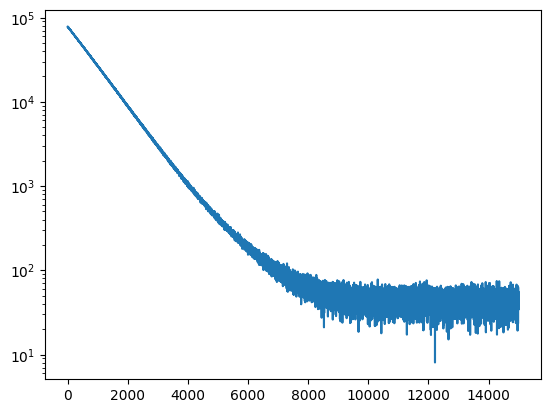

In [5]:
plt.plot(losses)
plt.yscale("log")

In [6]:
samples = posterior_samples(guide, params, 1000)

## Train multi-modal layered model

In [7]:
model_layered = LayeredRegBNN.from_data(X_train_main = X_train_main, Y_train_main = Y_train_main, X_train_aux = X_train_mm, Y_train_aux = Y_train_mm, hidden_widths=[256,256])
guide_layered = LayeredRegBNNGuide(model_layered)

In [8]:
adam_layered = pyro.optim.Adam({"lr": 0.001})
elbo_layered = pyro.infer.Trace_ELBO(num_particles = 1)

svi_layered = pyro.infer.SVI(model_layered, guide_layered, adam_layered, elbo_layered)
params_layered, losses_layered = do_svi(svi_layered, params = None)

2025-09-18 10:02:46 - Start
2025-09-18 10:03:35 - Step 1000, Elbo loss: 47740.6 +/- 29345.7 (slope = -50351.330 +/- 427.854 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:04:22 - Step 2000, Elbo loss: 16122.8 +/- 10090.8 (slope = -17297.003 +/- 154.870 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:05:12 - Step 3000, Elbo loss: 5403.3 +/- 3360.3 (slope = -5755.645 +/- 53.510 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:06:00 - Step 4000, Elbo loss: 1841.5 +/- 1122.8 (slope = -1920.812 +/- 18.868 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:06:49 - Step 5000, Elbo loss: 639.8 +/- 387.2 (slope = -658.789 +/- 7.865 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:07:40 - Step 6000, Elbo loss: 218.3 +/- 143.7 (slope = -237.251 +/- 4.722 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:08:31 - Step 7000, Elbo loss: 69.4 +/- 59.5 (slope = -85.275 +/- 3.654 loss/k-iter, p-value = 0.000) + 
2025-09-18 10:09:20 - Step 8000, Elbo loss: 15.2 +/- 36.7 (slope = -31.438 +/- 3.490 loss/k-iter, p-valu

In [9]:
samples_layered = posterior_samples(guide_layered, params_layered, 1000)

## Use botorch optimizer on fitted models

## Optimize expected improvement

In [10]:
from mmbo.optim import expected_improvement, lcb, probability_improvement, probability_improvement_sigmoid, expected_improvement_softplus
from mmbo.examples.testfunc import paciorek_hf, branin_hf
import botorch

In [ ]:
n_raw_samples = 1000

low_lim = torch.tensor([-5.0, 0.0])
high_lim = torch.tensor([10., 15.0])

# Paciorek
#X_init = torch.rand((n_swarm, 4)) * (high_lim - low_lim) + low_lim
# Branin
X_init = torch.rand((n_raw_samples, 2)) * (high_lim - low_lim) + low_lim

In [22]:
def select_next_point(objective, num_candidates, low_lim, high_lim, num_raw_samples=None, initial_samples=None):
    if num_raw_samples is None and initial_samples is None:
        raise ValueError("Must supply either num_raw_samples or initial_samples")
    if num_raw_samples is not None and initial_samples is not None:
        raise Warning("num_raw_samples is ignored if initial_samples is given")
    if initial_samples is None:
        initial_samples = torch.rand((num_raw_samples, 2)) * (high_lim - low_lim) + low_lim
    raw_objective = objective(initial_samples)
    _,bestidx = torch.topk(raw_objective.squeeze(), num_candidates)
    candidates = initial_samples[bestidx]
    final_samples,final_objective = botorch.gen_candidates_scipy(candidates, objective, low_lim, high_lim, options={"method":"SLSQP"})
    _,finalidx = torch.topk(final_objective.squeeze(), 1)
    return final_samples[finalidx]

### Uni-modal

In [23]:


objective = lambda x: expected_improvement(model, samples, x, Y_train_main.min())

num_points = 50

X_new = select_next_point(objective, num_points, low_lim, high_lim, initial_samples = X_init)
print(X_new)


tensor([[-5.0000, 12.0733]])


(0.0, 15.0)

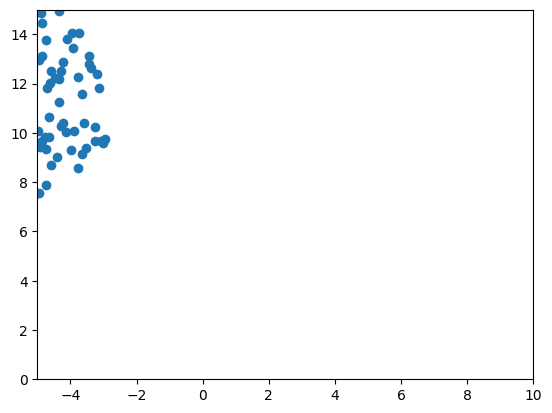

In [13]:
plt.scatter(candidates[:,0], candidates[:,1])
plt.xlim(low_lim[0], high_lim[0])
plt.ylim(low_lim[1], high_lim[1])

In [16]:
X_final,ei_final = botorch.gen_candidates_scipy(candidates, objective, low_lim, high_lim, options={"method":"SLSQP"})

tensor([[34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966],
        [34.8966]])

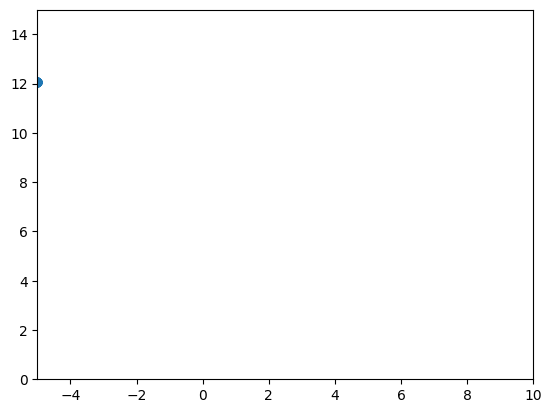

In [17]:
plt.scatter(X_final[:,0], X_final[:,1])
plt.xlim(low_lim[0], high_lim[0])
plt.ylim(low_lim[1], high_lim[1])
ei_final

### Layered Multi-modal

In [18]:
objective_layered = lambda x: expected_improvement(model_layered, samples_layered, x, Y_train_main.min())

raw_objective = objective_layered(X_init)
_,bestidx = torch.topk(raw_objective.squeeze(), num_points)
candidates_layered = X_init[bestidx]

(0.0, 15.0)

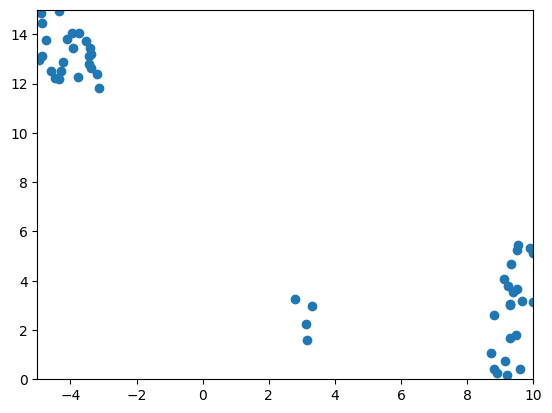

In [19]:
plt.scatter(candidates_layered[:,0], candidates_layered[:,1])
plt.xlim(low_lim[0], high_lim[0])
plt.ylim(low_lim[1], high_lim[1])

In [20]:
X_final_layered,ei_final_layered = botorch.gen_candidates_scipy(candidates_layered, objective_layered, low_lim, high_lim, options={"method":"SLSQP"})

tensor([[9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [9.9922],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [9.9922],
        [5.0017],
        [9.9922],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [9.9922],
        [5.0017],
        [5.0017],
        [5.0017],
        [5.0017],
        [9.9922],
        [5.0017],
        [3.5246],
        [5.0017],
        [9.9922],
        [5.0017],
        [5.0017],
        [9.9922],
        [5.0017],
        [9.9922],
        [5.0017],
        [9.9922],
        [9.9922],
        [3.5247],
        [0.0000],
        [0.0000]])

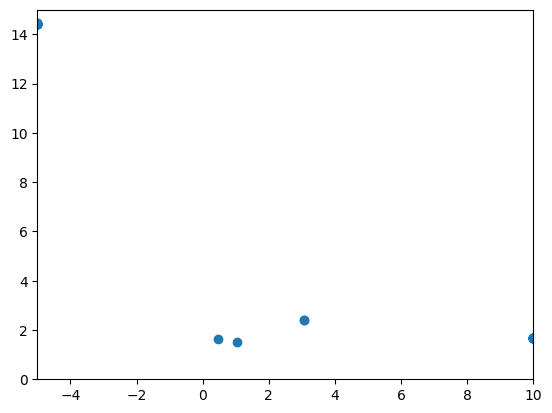

In [21]:
plt.scatter(X_final_layered[:,0], X_final_layered[:,1])
plt.xlim(low_lim[0], high_lim[0])
plt.ylim(low_lim[1], high_lim[1])
ei_final_layered